In [7]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

In [8]:
r2_data = pd.read_csv("5-Water-R2.csv", header=None)
entg_expr_data = pd.read_csv("ExprAndEntg.csv", header=None)
r2_data.columns = ["Model_Type", "Circuit_Name", "R2"]
entg_expr_data.columns = ["Circuit_Name", "Expr", "Entg"]
circuits = r2_data["Circuit_Name"][2:]

def name_mapping(name_to_map):
    circuit_list = name_to_map.split("-")
    circuit_name = circuit_list[0]
    if circuit_name == "Classical":
        return "Classical SVR"
    try:
        name_mapping = {
        'CP_map': 'CPMap',
        'ZZ_map': 'ZZFeaturemap',
        'ParamZ': 'ParamZ',
        'Hubregtsen': 'Hubregtsen',
        'HighDim': 'HighDim',
        'MultiControl': 'MultiControl',
        'Chebyshev': 'ChebyshevPQC',
        'YZ_CX': 'YZ-CX',
        }
        new_name = f"{name_mapping.get(circuit_name, circuit_name)}-{circuit_list[1].upper()}-{circuit_list[2]}"
    except Exception as e:
        print(e)
        print(circuit_name)
    return new_name

circuits = circuits.apply(lambda x: name_mapping(x))
r2_data["Circuit_Name"] = circuits
print(r2_data[r2_data['Circuit_Name'] == "Classical SVR"])

    Model_Type   Circuit_Name        R2
19   False-krr  Classical SVR  0.999450
564  False-krr  Classical SVR  0.999450
760        NaN  Classical SVR -1.322751


In [9]:
plot_circuit_data = entg_expr_data.copy()
split_data = plot_circuit_data['Circuit_Name'].str.split('-', n=2, expand=True)

if split_data.shape[1] >= 1:
    plot_circuit_data['Name_base'] = split_data[0]
if split_data.shape[1] >= 2:
    plot_circuit_data['Function'] = split_data[1]
if split_data.shape[1] >= 3:
    plot_circuit_data['Layers'] = split_data[2]

plot_circuit_data['Name_base'] = plot_circuit_data['Name_base'].astype('category')
plot_circuit_data = plot_circuit_data[plot_circuit_data["Name_base"] != "ParamZFeatureMapNO"]
plot_circuit_data['Function'] = plot_circuit_data['Function'].astype('category')
plot_circuit_data['Function'] = plot_circuit_data['Function'].replace('0', 'Original')

print("Processed data head (plot_data):")
print(plot_circuit_data.head())
print("\nData types of new columns:")
print(plot_circuit_data[['Name_base', 'Function', 'Layers']].dtypes)

print("\nUnique Name_base values and their counts:")
print(plot_circuit_data['Name_base'].value_counts())
print(f"Total unique Name_base values: {plot_circuit_data['Name_base'].nunique()}")

star_path = "M0,-1.25 L0.3,-0.4 L1.1875,-0.4 L0.6,0.15 L0.85,1.025 L0,0.525 L-0.85,1.025 L-0.6,0.15 L-1.1875,-0.4 L-0.3,-0.4 Z"

# Define the final list of shapes
final_shapes = ['circle', 'square', 'cross', 'diamond', 'triangle-up', 'stroke', 'arrow', star_path]

category_mapping = {
    'Original': {'row_facet': 'Original', 'col_facet': 'Original'},
    '1': {'row_facet': 'Original', 'col_facet': 'Degree 1'},
    '2': {'row_facet': 'Degree 2', 'col_facet': 'Original'},
    'ATAN': {'row_facet': 'ARCTAN', 'col_facet': 'Original'}
}

facet_title_mapping = {
    'Original': 'Original',
    '1': 'Degree 1',
    '2': 'Degree 2',
    'ATAN': 'ARCTAN'
}

plot_circuit_data['facet_title'] = plot_circuit_data['Function'].map(facet_title_mapping)

# This mapping helps control the order of the facets
plot_circuit_data['facet_order'] = plot_circuit_data['Function'].map({'Original': 0, '1': 1, '2': 2, 'ATAN': 3})

# Apply the mapping to create new columns
plot_circuit_data['row_facet'] = plot_circuit_data['Function'].map(lambda x: category_mapping[x]['row_facet'])
plot_circuit_data['col_facet'] = plot_circuit_data['Function'].map(lambda x: category_mapping[x]['col_facet'])
print(plot_circuit_data.head())

Processed data head (plot_data):
                    Circuit_Name      Expr      Entg  \
0  HubregtsenEncodingCircuit-0-1  0.075368  0.460330   
1  HubregtsenEncodingCircuit-0-2  0.035521  0.573513   
2  HubregtsenEncodingCircuit-1-1  0.091957  0.456529   
3  HubregtsenEncodingCircuit-1-2  0.037306  0.583424   
4  HubregtsenEncodingCircuit-2-1  0.091877  0.457889   

                   Name_base  Function Layers  
0  HubregtsenEncodingCircuit  Original      1  
1  HubregtsenEncodingCircuit  Original      2  
2  HubregtsenEncodingCircuit         1      1  
3  HubregtsenEncodingCircuit         1      2  
4  HubregtsenEncodingCircuit         2      1  

Data types of new columns:
Name_base    category
Function     category
Layers         object
dtype: object

Unique Name_base values and their counts:
Name_base
CPMap                          8
ChebyshevPQC                   8
HighDimEncodingCircuit         8
HubregtsenEncodingCircuit      8
MultiControlEncodingCircuit    8
ParamZFeatureMap

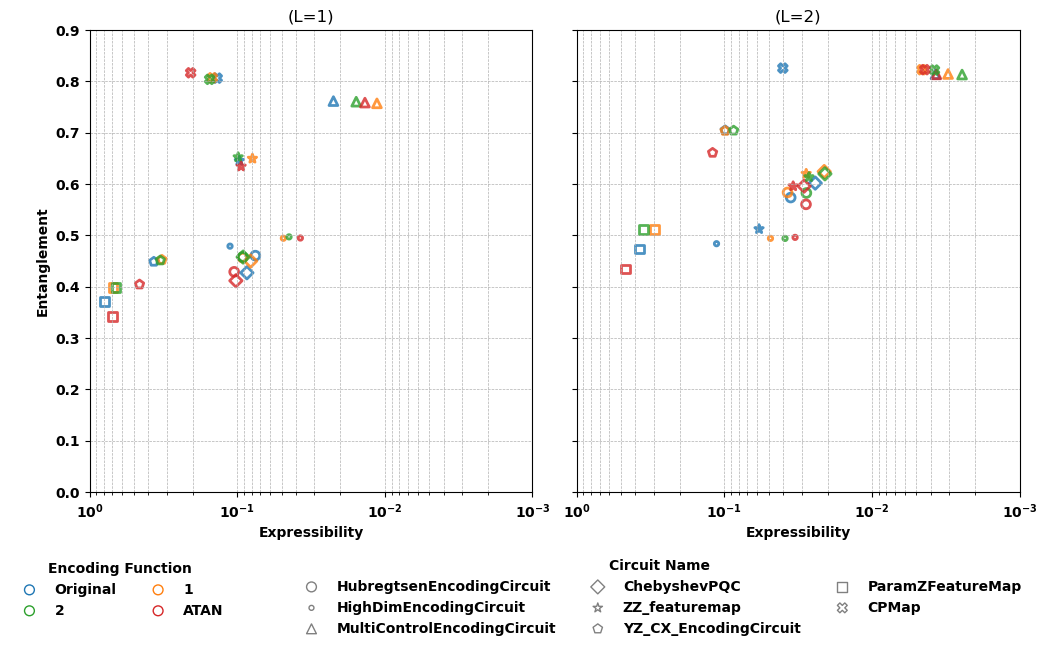

In [10]:
plt.rcParams.update({'font.size': 10, 'font.weight':'heavy'})

markers = ['o', '.', '^', 'D', '*', 'p', 's', 'X']
circuits = plot_circuit_data['Name_base'].unique()
circuit_marker_map = dict(zip(circuits, markers))

# Define a list of colors for the functions
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']
functions = plot_circuit_data['Function'].unique()
function_color_map = dict(zip(functions, colors))

circuit_handles_labels = {}
function_handles_labels = {}
# Define Legend Ordering
circuit_order = circuits.tolist()
function_order = ["Original", "2", "1", "ATAN"] 

fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharey=True)
plt.subplots_adjust(wspace=0.1)

# Plotting for RUD 1
ax1 = axes[0]
df_rud1 = plot_circuit_data[plot_circuit_data['Layers'] == '1']
for circuit in circuits:
    for function in functions:
        subset = df_rud1[(df_rud1['Name_base'] == circuit) & (df_rud1['Function'] == function)]
        if not subset.empty:
            ax1.scatter(
                subset['Expr'],
                subset['Entg'],
                s=40,
                marker=circuit_marker_map[circuit],
                facecolors="None",
                edgecolors=function_color_map[function],
                label=f"{circuit} ({function})",
                linewidths=2,
                alpha=0.8
            )
        if circuit not in circuit_handles_labels:
                    # Create a dummy scatter to represent the marker in the legend with a neutral color
                    dummy_marker = ax1.scatter([], [], marker=circuit_marker_map[circuit], 
                                                s=50, edgecolors='gray', facecolors='none', linewidths=1)
                    circuit_handles_labels[circuit] = (dummy_marker, circuit)

        if function not in function_handles_labels:
            dummy_color = ax1.scatter([], [], marker='o', 
                                        s=50, edgecolors=function_color_map[function], 
                                        facecolors='none', linewidths=1)
            function_handles_labels[function] = (dummy_color, function)
ax1.set_xscale('log')
ax1.set_xlim(1, 0.001)
ax1.set_ylim(0, 0.9)
ax1.set_title('(L=1)')
ax1.set_ylabel('Entanglement')
ax1.set_xlabel('Expressibility')
ax1.grid(True, which="both", ls="--", linewidth=0.5)

# Plotting for RUD 2
ax2 = axes[1]
df_rud2 = plot_circuit_data[plot_circuit_data['Layers'] == '2']
for circuit in circuits:
    for function in functions:
        subset = df_rud2[(df_rud2['Name_base'] == circuit) & (df_rud2['Function'] == function)]
        if not subset.empty:
            ax2.scatter(
                subset['Expr'],
                subset['Entg'],
                s=40,
                marker=circuit_marker_map[circuit],
                facecolors="None",
                edgecolors=function_color_map[function],
                label=f"{circuit} ({function})",
                linewidths=2,
                alpha=0.8
            )
ax2.set_xscale('log')
ax2.set_xlim(1, 0.001)
ax2.set_ylim(0, 0.9)
ax2.set_title('(L=2)')
ax2.set_xlabel('Expressibility')
ax2.grid(True, which="both", ls="--", linewidth=0.5)

# Color - Function
func_handles = [function_handles_labels[f][0] for f in function_order if f in function_handles_labels]
func_labels = [f for f in function_order if f in function_handles_labels]
legend_func = fig.legend(func_handles, func_labels, 
                         loc='lower center', 
                         title='Encoding Function', 
                         ncol=2, # Arrange horizontally
                         frameon=False,
                         bbox_to_anchor=(0.15, -0.12)) # Adjust position under left plot

# Markers - Circuits
circ_handles = [circuit_handles_labels[c][0] for c in circuit_order if c in circuit_handles_labels]
circ_labels = [c for c in circuit_order if c in circuit_handles_labels]

legend_circ = fig.legend(circ_handles, circ_labels, 
                         loc='lower center', 
                         title='Circuit Name', 
                         ncol=3, # Arrange in 3 columns for better layout
                         frameon=False,
                         bbox_to_anchor=(0.6, -0.15)) # Adjust position under right plot

plt.savefig('express_entg.png', dpi=450, bbox_inches='tight')

In [11]:
import warnings

warnings.filterwarnings("ignore")

r2_data = pd.read_csv("5-Water-R2.csv", header=None)
entg_expr_data = pd.read_csv("ExprAndEntg.csv", header=None)
r2_data.columns = ["Model_Type", "Circuit_Name", "R2"]
model_type = r2_data['Model_Type']

def name_mapping(row):
    name_to_map = row["Circuit_Name"]
    model_type = row["Model_Type"]
    circuit_list = name_to_map.split("-")
    circuit_name = circuit_list[0]
    if circuit_name == "Classical":
        return "Classical"
    name_mapping = {
    'CP_map': 'CPMap',
    'ZZ_map': 'ZZFeaturemap',
    'ParamZ': 'ParamZ',
    'Hubregtsen': 'Hubregtsen',
    'HighDim': 'HighDim',
    'MultiControl': 'MultiControl',
    'Chebyshev': 'ChebyshevPQC',
    'YZ_CX': 'YZ_CX'
    }
    if "False" in model_type:
        new_name = f"{name_mapping.get(circuit_name, circuit_name)}-{circuit_list[1].upper()}-{circuit_list[2]}-{circuit_list[3]}"
    else:
        new_name = f"{name_mapping.get(circuit_name, circuit_name)}-{circuit_list[1].upper()}-{circuit_list[2]}"
    return new_name

r2_data["Circuit_Name"] = r2_data.apply(name_mapping, axis=1)

df_contains_true = r2_data[r2_data['Model_Type'].str.contains('True', na=False)]
df_contains_false = r2_data[r2_data['Model_Type'].str.contains('False', na=False)]

split_data = df_contains_true['Circuit_Name'].str.split('-', n=2, expand=True)
split_model = df_contains_true["Model_Type"].str.split("-")
if split_data.shape[1] >= 1:
    df_contains_true['Name_base'] = split_data[0]
if split_data.shape[1] >= 2:
    df_contains_true['Function'] = split_data[1]
if split_data.shape[1] >= 3:
    df_contains_true['Layers'] = split_data[2]
    
split_data = df_contains_false['Circuit_Name'].str.split('-', n=3, expand=True)
split_model =df_contains_false["Model_Type"].str.split("-")
if split_data.shape[1] >= 1:
    df_contains_false['Name_base'] = split_data[0]
if split_data.shape[1] >= 2:
    df_contains_false['Function'] = split_data[1]
if split_data.shape[1] >= 3:
    df_contains_false['Layers'] = split_data[2]
if split_data.shape[1] >= 4:
    df_contains_false["Job_Num"] = split_data[3]
    

df_contains_true["Model_Type"] = df_contains_true["Model_Type"].str.replace("True-", "", regex=False)
df_contains_false["Model_Type"] = df_contains_false['Model_Type'].str.replace("False-", "", regex=False)
df_contains_true['Name_base'] = df_contains_true['Name_base'].astype('category')
df_contains_true['Function'] = df_contains_true['Function'].astype('category')
df_contains_false['Name_base'] = df_contains_false['Name_base'].astype('category')
df_contains_false['Function'] = df_contains_false['Function'].astype('category')


df_contains_false['Circuit_Name'] = (
    df_contains_false['Circuit_Name']
    .astype(str)
    .str.replace(r'-\d+$', '', regex=True)
)

df_contains_false = df_contains_false[df_contains_false["Name_base"] != "Classical"]
grouping_cols = ['Model_Type', 'Name_base', 'Function', 'Layers']

# Group by the identifying columns and aggregate
consolidated_df = df_contains_false.groupby(grouping_cols).agg(
    # Take the first Circuit_Name encountered for this group as a representative.
    Circuit_Name=('Circuit_Name', 'first'),

    # Create a dictionary mapping Job_Num to R2 for each section
    R2_values=('R2', list)
).reset_index()

# Reorder columns for better readability if desired
consolidated_df = consolidated_df[['Model_Type', 'Name_base', 'Function', 'Layers', 'R2_values']]
consolidated_df = consolidated_df[consolidated_df["Name_base"] != "Classical"]
print("Consolidated DataFrame:")
print(consolidated_df.head(10))


Consolidated DataFrame:
  Model_Type     Name_base Function Layers  \
0       qkrr         CPMap        0      1   
1       qkrr         CPMap        0      2   
2       qkrr         CPMap        1      1   
3       qkrr         CPMap        1      2   
4       qkrr         CPMap        2      1   
5       qkrr         CPMap        2      2   
6       qkrr         CPMap     ATAN      1   
7       qkrr         CPMap     ATAN      2   
8       qkrr  ChebyshevPQC        0      1   
9       qkrr  ChebyshevPQC        0      2   

                                           R2_values  
0  [0.9939890763145776, 0.9939275513713788, 0.993...  
1  [0.9961624068638498, 0.996193240940948, 0.9960...  
2  [0.9961102878387704, 0.996078799807433, 0.9961...  
3  [0.9980749817990324, 0.9981275836890828, 0.998...  
4  [0.9921217968361588, 0.991139388923035, 0.9920...  
5  [0.9981970748595844, 0.9985115315557554, 0.998...  
6  [0.983550657250196, 0.983016691985524, 0.98274...  
7  [0.9917599479966456, 0.991

In [ ]:
import matplotlib.image as mpimg
from matplotlib.offsetbox import OffsetImage, AnchoredOffsetbox
plt.rcParams.update({'font.size': 10, 'font.weight':'heavy'})
trained_df = df_contains_true.copy()
performance_df = consolidated_df.copy()
properties_df = entg_expr_data.copy()

print(performance_df.head())

# Preprocessing performance_df (untrained models)
performance_df = performance_df.explode('R2_values')
performance_df['R2'] = performance_df['R2_values'].astype(float)
performance_df['Trained'] = False
performance_df['Function'] = performance_df['Function'].astype(str)
performance_df['Layers'] = performance_df['Layers'].astype(str)

# Preprocessing trained_df
trained_df['Trained'] = True
trained_df['Function'] = trained_df['Function'].astype(str)
trained_df['Layers'] = trained_df['Layers'].astype(str)

# Define the extraction function
def extract_circuit_parts(circuit_str):
    parts = circuit_str.split('-')
    # Assuming the last two parts are Function and Layers
    layers = parts[-1]
    function = parts[-2]
    name_base = '-'.join(parts[:-2])
    return name_base, function, layers

# Apply extraction first
properties_df[['Name_base', 'Function', 'Layers']] = properties_df[0].apply(lambda x: pd.Series(extract_circuit_parts(x)))
properties_df.drop(columns=[0], inplace=True)

# Ensure 'Function' and 'Layers' columns in properties_df are string type
properties_df['Function'] = properties_df['Function'].astype(str)
properties_df['Layers'] = properties_df['Layers'].astype(str)

# Combine all performance dataframes
all_performance_df = pd.concat([performance_df.drop(columns=['R2_values']), trained_df.drop(columns=['Circuit_Name'])], ignore_index=True)

# Create a common key for merging
all_performance_df['Circuit_Key'] = all_performance_df['Name_base'] + '_' + all_performance_df['Function'] + '_' + all_performance_df['Layers']
properties_df['Circuit_Key'] = properties_df['Name_base'] + '_' + properties_df['Function'] + '_' + properties_df['Layers']

# Merge the dataframes
merged_df = pd.merge(all_performance_df, properties_df, on='Circuit_Key', how='left')
merged_df.drop(columns=['Circuit_Key'], inplace=True)

# Clean up merged columns
for col_base in ['Name_base', 'Function', 'Layers']:
    if f'{col_base}_x' in merged_df.columns and f'{col_base}_y' in merged_df.columns:
        merged_df.drop(columns=[f'{col_base}_y'], inplace=True)
        merged_df.rename(columns={f'{col_base}_x': col_base}, inplace=True)
    elif f'{col_base}_x' in merged_df.columns and f'{col_base}_y' not in merged_df.columns:
        merged_df.rename(columns={f'{col_base}_x': col_base}, inplace=True)
    elif f'{col_base}_y' in merged_df.columns and f'{col_base}_x' not in merged_df.columns:
         merged_df.rename(columns={f'{col_base}_y': col_base}, inplace=True)

# Create the specific 'Encoding Scheme' column (for reference, but not directly used in new faceted plots for legend)
merged_df['Encoding_Scheme'] = merged_df['Name_base'] + '  (L=' + merged_df['Layers'] + ')'

merged_df["Function"] = merged_df["Function"].replace("0", "Original")
# Display the merged dataframe info and head to verify
print("Merged DataFrame Info (Final):")
print(merged_df.info())
print("\nMerged DataFrame Head (Final):")
print(merged_df.head())

category_mapping = {
    'Original': {'row_facet': 'Top', 'col_facet': 'Left'},
    '1': {'row_facet': 'Top', 'col_facet': 'Right'},
    '2': {'row_facet': 'Bottom', 'col_facet': 'Left'},
    'ATAN': {'row_facet': 'Bottom', 'col_facet': 'Right'}
}

# Apply the mapping to create new columns
merged_df['row_facet'] = merged_df['Function'].map(lambda x: category_mapping[x]['row_facet'])
merged_df['col_facet'] = merged_df['Function'].map(lambda x: category_mapping[x]['col_facet'])


sns.set_palette(["#1a80BB", "#ea801C"])

g = sns.catplot(
    data=merged_df,
    kind="box",
    x='Encoding_Scheme',
    y='R2',
    row="row_facet",
    col="col_facet",
    hue='Trained',
    height=4,
    aspect=1.5,
    sharex=True,
    sharey=False,
    legend=False
)

num_to_category = {
    "00" : "Original",
    "01": "Degree 1",
    "10" : "Degree 2",
    "11" : "ARCTAN"
}
g.set_xlabels("")

# Iterate through the axes
for row_idx, row_axes in enumerate(g.axes):
    for col_idx, ax in enumerate(row_axes):
        original_function_name = num_to_category[f"{row_idx}{col_idx}"]
        ax.set_title(original_function_name, fontsize=12, fontweight="bold")
        if col_idx == 0 and row_idx == 1:
            ax.set_ylim(0.96, 1.0)
        elif col_idx == 1 and row_idx == 1:
            ax.set_ylim(0.96, 1.0)

        ax.set_ylabel('$R^2$')
        ax.grid(axis='y', linestyle='--', alpha=0.7)

        if row_idx == 1:
            ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right', fontweight="bold")
            ax.tick_params(axis='x', which='both', bottom=True, top=False, labelbottom=True) # Hide ticks and labels
        ax.grid(axis='x')
        num_categories = len(ax.get_xticks())

        boundaries = np.arange(-0.5, num_categories, 1) + 0.5
        shade_color = 'grey' 
        alpha_value = 0.15 # Use a transparency (alpha) value

        for i in range(0, num_categories, 2):
            if i + 1 < num_categories:

                # Shade the area corresponding to the category at index i + 1
                x_start = i + 0.5
                x_end = i + 1.5
                ax.axvspan(x_start, x_end, facecolor=shade_color, alpha=alpha_value, zorder=0)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.rcParams.update({'axes.labelweight': "bold"})
plt.savefig('Water_R2_score.png', dpi=300, bbox_inches='tight')
plt.close()

  Model_Type Name_base Function Layers  \
0       qkrr     CPMap        0      1   
1       qkrr     CPMap        0      2   
2       qkrr     CPMap        1      1   
3       qkrr     CPMap        1      2   
4       qkrr     CPMap        2      1   

                                           R2_values  
0  [0.9939890763145776, 0.9939275513713788, 0.993...  
1  [0.9961624068638498, 0.996193240940948, 0.9960...  
2  [0.9961102878387704, 0.996078799807433, 0.9961...  
3  [0.9980749817990324, 0.9981275836890828, 0.998...  
4  [0.9921217968361588, 0.991139388923035, 0.9920...  
Merged DataFrame Info (Final):
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 758 entries, 0 to 757
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Model_Type       758 non-null    object 
 1   Name_base        758 non-null    object 
 2   Function         758 non-null    object 
 3   Layers           758 non-null    object 
 4   R